# Validation vs Test — Market Regime Diagnostics (2024)

**Research question:** Why did forecast errors rise between July–September (validation) and October–December (test)?

This is **post-hoc, descriptive analysis**, not model selection or hyperparameter tuning. The October–December period had already been inspected in earlier work. We will not use any finding here to revise the models or feature set reported in notebooks 03 and 04.

Prices are in **EUR/MWh**. GME market hours are preserved, including daylight-saving transitions.


## 1. Load and validate the original GME prices

Place the official workbook at `../data/Anno 2024_12.xlsx` when running from `notebooks/`. The original workbook is not redistributed with the repository.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

workbook = Path("../data/Anno 2024_12.xlsx")
if not workbook.exists():
    raise FileNotFoundError(f"Missing workbook: {workbook.resolve()}")

raw = pd.read_excel(workbook, sheet_name="Prezzi-Prices")
prices = raw.iloc[:, :3].copy()
prices.columns = ["date", "hour", "price"]
prices["date"] = pd.to_datetime(prices["date"].astype(str), format="%Y%m%d")
prices["price"] = pd.to_numeric(prices["price"], errors="raise")
prices = prices.sort_values(["date", "hour"]).reset_index(drop=True)
assert len(prices) == 8784
assert prices["date"].nunique() == 366
assert not prices[["date", "hour", "price"]].isna().any().any()
assert not prices.duplicated(["date", "hour"]).any()
print("Observations:", len(prices))
print("Calendar days:", prices["date"].nunique())
print("Hours per day:", prices.groupby("date").size().value_counts().sort_index().to_dict())


Observations: 8784
Calendar days: 366
Hours per day: {23: 1, 24: 364, 25: 1}


## 2. Compare the observed price distributions

To match the evaluation sample in notebooks 03 and 04, the first eight calendar days are excluded. The warm-up interval is outside both comparison periods, so it does not change their observations.

Standard deviation measures dispersion of **price levels**, not necessarily day-to-day volatility. The next section examines changes between days separately.


In [3]:
validation = prices[(prices["date"] >= "2024-07-01") & (prices["date"] < "2024-10-01")].copy()
test = prices[(prices["date"] >= "2024-10-01") & (prices["date"] < "2025-01-01")].copy()
print("Validation observations:", len(validation))
print("Test observations:", len(test))

def describe_period(label, frame):
    p = frame["price"]
    return {"Period": label, "Observations": len(p), "Mean": p.mean(),
            "Median": p.median(), "Std dev": p.std(),
            "Min": p.min(), "P05": p.quantile(.05),
            "P95": p.quantile(.95), "Max": p.max()}

period_stats = pd.DataFrame([
    describe_period("Validation (Jul–Sep)", validation),
    describe_period("Test (Oct–Dec)", test),
]).set_index("Period")
print(period_stats.round(3).to_string())


Validation observations: 2208
Test observations: 2209
                      Observations     Mean  Median  Std dev    Min     P05      P95      Max
Period                                                                                       
Validation (Jul–Sep)          2208  119.317  113.50   26.451  0.967  91.280  175.771  250.000
Test (Oct–Dec)                2209  127.506  123.35   28.515  6.000  91.272  173.406  275.124


## 3. Visual comparison of distributions

The two periods have nearly the same number of hourly observations; the test period includes one additional hour due to the daylight saving time transition.


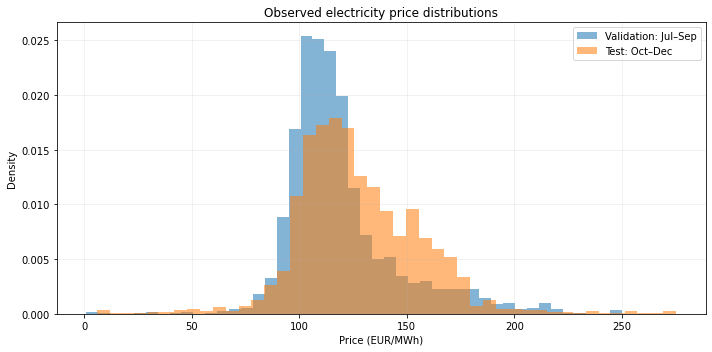

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(validation["price"], bins=45, alpha=0.55, density=True, label="Validation: Jul–Sep")
ax.hist(test["price"], bins=45, alpha=0.55, density=True, label="Test: Oct–Dec")
ax.set(title="Observed electricity price distributions", xlabel="Price (EUR/MWh)", ylabel="Density")
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


## 4. Monthly market conditions

Monthly price levels and dispersion help identify whether December differs from the rest of the evaluation period.


         observations     mean   median     std  minimum  maximum
month                                                            
2024-07           744  112.320  105.839  20.787   65.158  185.904
2024-08           744  128.435  119.881  25.577   97.680  250.000
2024-09           720  117.126  110.000  29.724    0.967  217.244
2024-10           745  116.688  113.548  23.527    8.563  187.461
2024-11           720  130.889  127.870  21.434   83.530  193.000
2024-12           744  135.065  130.220  35.098    6.000  275.124


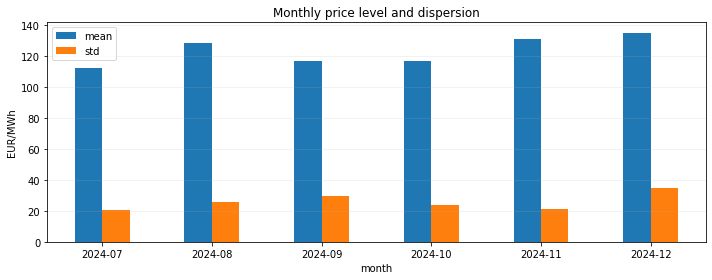

In [5]:
monthly = prices[(prices["date"] >= "2024-07-01") & (prices["date"] < "2025-01-01")].copy()
monthly["month"] = monthly["date"].dt.strftime("%Y-%m")
monthly_stats = monthly.groupby("month")["price"].agg(
    observations="count", mean="mean", median="median", std="std", minimum="min", maximum="max"
)
print(monthly_stats.round(3).to_string())
ax = monthly_stats[["mean", "std"]].plot.bar(figsize=(10, 4), rot=0,
    title="Monthly price level and dispersion")
ax.set_ylabel("EUR/MWh")
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()


## 5. Same-hour calendar-day price changes

As a simple measure of **realized price movement**, compare each market hour with the same hour on the previous calendar day. This measure is **descriptive only**: it is *not* an allowed forecasting input at 12:00 on D−1. Date-and-hour joins handle daylight-saving transitions without positional misalignment.


In [6]:
previous = prices[["date", "hour", "price"]].copy()
previous["date"] = previous["date"] + pd.Timedelta(days=1)
previous = previous.rename(columns={"price": "previous_day_price"})
changes = prices.merge(previous, on=["date", "hour"], how="left", validate="one_to_one")
changes["abs_daily_change"] = (changes["price"] - changes["previous_day_price"]).abs()
changes = changes[(changes["date"] >= "2024-07-01") & (changes["date"] < "2025-01-01")].copy()
changes["period"] = np.where(changes["date"] < "2024-10-01", "Validation", "Test")
changes["month"] = changes["date"].dt.strftime("%Y-%m")
print("Absolute same-hour day-to-day price change by period:")
print(changes.groupby("period")["abs_daily_change"].agg(["count", "mean", "median", "std"]).round(3).to_string())
print("\nBy month:")
print(changes.groupby("month")["abs_daily_change"].agg(["count", "mean", "median"]).round(3).to_string())


Absolute same-hour day-to-day price change by period:
            count    mean  median     std
period                                   
Test         2208  12.381   8.739  13.263
Validation   2208  10.726   6.396  13.403

By month:
         count    mean  median
month                         
2024-07    744   9.631   6.252
2024-08    744   7.672   5.028
2024-09    720  15.013   9.230
2024-10    744  10.790   7.702
2024-11    720   9.414   7.351
2024-12    744  16.845  11.549


## 6. Relate market conditions to observed forecast errors

The validated notebook 04 reported these MAE values (EUR/MWh), reproduced here **as previously observed results**, not recomputed from predictions:

| Model | Validation (Jul–Sep) | Test (Oct–Dec) |
|---|---:|---:|
| Linear regression | 10.664 | 13.295 |
| Random Forest | 11.762 | 13.052 |
| D−2 historical baseline | 12.678 | 16.657 |

December test MAE was 19.659 for linear regression and 19.019 for Random Forest, compared with approximately 8.7–8.9 in November. Changes in observed price dispersion or day-to-day movements may **coincide** with these error differences, but this descriptive analysis cannot prove why the models performed differently.

**Interpretation guardrails:** avoid choosing a different model or adding features using this already-inspected test period. More reliable evidence would require additional forward periods or rolling-origin evaluation with predeclared selection rules.


## 7. Conclusions

The comparison between validation (July–September 2024) and test (October–December 2024) reveals measurable differences in observed electricity market conditions.

- **Higher price levels:** the average hourly electricity price increased from 119.317 EUR/MWh in validation to 127.506 EUR/MWh in test.
- **Greater dispersion:** the standard deviation of hourly price levels increased from 26.451 to 28.515 EUR/MWh.
- **Larger day-to-day movements:** the mean absolute same-hour day-to-day price change increased from 10.726 to 12.381 EUR/MWh, approximately 15.4%.
- **December stands out:** December had the highest monthly price standard deviation (35.098 EUR/MWh) and the largest mean absolute day-to-day movement (16.845 EUR/MWh) among the six months examined.

These observations are consistent with the higher forecasting errors reported for the test period, particularly in December. However, they do not establish a causal explanation for the deterioration in predictive accuracy. Changes in price levels, dispersion, and day-to-day movements describe different aspects of market conditions.

The model selected on validation remains Linear Regression. Although Random Forest achieved a slightly lower MAE on the previously inspected test period, this result does not justify changing the model selection retrospectively.

**Limitations:** this analysis is descriptive, covers only six months, and uses an already inspected test period. Stronger conclusions would require additional future observations or rolling-origin evaluation with predefined model-selection rules.

**Next research phase — Milestone 6:** investigate ex-ante electricity demand, renewable generation, and weather forecasts, verifying that every external input was published before the 12:00 forecast issuance deadline.
